# Factorial Planes

To help understanding the following articles:

- [4.1 Lascaux Cave Temperatures](https://pca4ds.github.io/lascaux.html)
- [4.3 Defining an Economic Capacity Index](https://pca4ds.github.io/defining-an-economic-capacity-index.html)

## PCA: Factorial Planes, Eigenvalues and Correlation Circles

### 1. What is a factorial plane?

A **factorial plane** is a two-dimensional space formed by two principal components (PCs).

In PCA, the first factorial plane consists of:

- **PC1 (horizontal axis):** The direction explaining the greatest variance.
- **PC2 (vertical axis):** The direction explaining the greatest remaining variance, orthogonal to PC1.

Each principal component corresponds to an **eigenvector** of the covariance or correlation matrix, and its **eigenvalue** measures the variance explained along that direction.

### 2. Circle of correlations

A **circle of correlations** represents the relationships between the original variables and the principal components.

Each arrow represents an original variable. Its coordinates correspond to the correlations between that variable and PC1 and PC2.

![Figure 4.10: Circle of correlations of economic indicators](./images/week_4/figure-4-10.png)

*Figure 4.10: Circle of correlations of economic indicators. Source: [Principal Component Analysis for Data Science](https://pca4ds.github.io/defining-an-economic-capacity-index.html).*

For an original variable $X_j$, the arrow's coordinates are:

$$
x=\operatorname{Corr}(X_j,PC1)
$$

$$
y=\operatorname{Corr}(X_j,PC2)
$$

These correlations range between $-1$ and $1$.

The circle has a **radius of 1**, representing the maximum possible combined correlation magnitude with the selected two principal components.

#### Interpreting arrow directions

- **Similar directions:** Variables are positively correlated.
- **Opposite directions:** Variables are negatively correlated.
- **Approximately perpendicular directions:** Variables have weak or zero correlation, provided they are well represented on the plane.

The closer an arrow is to the circumference, the more reliably its direction can be used to interpret relationships with other well-represented variables.

### 3. Why are most arrows close to the circumference?

The distance of an arrow from the origin indicates how well the original variable is represented by the selected principal components.

For a standardised variable:

$$
r^2 =
\operatorname{Corr}(X_j,PC1)^2
+
\operatorname{Corr}(X_j,PC2)^2
$$

This quantity is also called the **squared cosine (cos²)** or *quality of representation*.

It represents the proportion of the original variable's variance explained by PC1 and PC2 together.

For example, suppose:

$$
\operatorname{Corr}(X_j,PC1)=0.9
$$

$$
\operatorname{Corr}(X_j,PC2)=0.4
$$

Then:

$$
r^2=0.9^2+0.4^2=0.97
$$

$$
r=\sqrt{0.97}\approx0.985
$$

**Interpretation:** The variable is represented almost perfectly on the first factorial plane because PC1 and PC2 together explain 97% of its variance.

A variable near the centre of the circle is poorly represented on this plane. It may be better represented by later principal components.

### 4. How are eigenvalues related to the circle?

**Eigenvalues and arrow lengths describe different properties of PCA.**

- **Eigenvalues:** Measure how much total variance each principal component explains.
- **Arrow lengths:** Measure how much of an individual variable's variance is captured by the selected components.

For standardised PCA, the eigenvalue of component $k$ is:

$$
\lambda_k =
\sum_{j=1}^{p}
\operatorname{Corr}(X_j,PC_k)^2
$$

Therefore, an eigenvalue is the sum of squared correlations of all original variables with that component.

For the six economic indicators in Figure 4.10:

| Component | Eigenvalue | Explained variance |
|---|---:|---:|
| PC1 | 4.3235 | 72.06% |
| PC2 | 0.6800 | 11.33% |
| **Combined** | **5.0035** | **83.39%** |

Although PC2 has a relatively small eigenvalue, most variables can still lie close to the circumference because **PC1 already captures a substantial proportion of their variance**.

A small eigenvalue for PC2 does not imply that the arrows must be short.

### 5. Another example: Lascaux Cave temperatures

![Figure 4.2: Circle of correlations of Lascaux Cave temperatures](./images/week_4/figure-4-2.png)

*Figure 4.2: Circle of correlations of temperature measurements. Source: [Lascaux Cave Temperatures](https://pca4ds.github.io/lascaux.html).*

This figure shows the original temperature variables projected onto PC1 and PC2.

Observe that:

- Many arrows lie close to the circumference, meaning those temperature variables are well represented by the first two principal components.
- Arrows pointing in similar directions represent temperature measurements with similar variation patterns.
- Arrows pointing in opposite directions suggest negatively correlated temperature measurements.
- Some arrows are shorter, indicating that the first two components do not capture all the variation of those measurements.

In this example, PC1 explains approximately 49.57% and PC2 explains 30.13% of the total variance.

Together, they explain approximately 79.69%.

### 6. Conclusions

1. A **factorial plane** is a two-dimensional space defined by two principal components, typically PC1 and PC2.

2. A **correlation circle** displays how the original variables relate to those components.

3. The **length of an arrow** indicates how well a variable is represented on the factorial plane, not its eigenvalue.

4. Arrows near the circumference indicate that the first two components explain almost all the variance of those individual variables.

5. **Eigenvalues measure variance explained across the dataset**, whereas squared arrow lengths measure the proportion of variance explained for individual variables.

6. A small eigenvalue for PC2 does not prevent variables from lying near the circumference if PC1 already explains most of their variance.

7. The **angles between arrows** help us understand correlations between original variables, particularly when their arrows lie close to the circumference.

**Key takeaway:** Eigenvalues describe the importance of principal components, while correlation-circle arrow lengths describe how accurately the selected components represent each original variable.


## Visual example

### Correlation circle calculations

,Variable,PC1,PC2,PC1²,PC2²,r²,r,Explained (%)
0,A,0.9,0.40,0.81,0.1600,0.9700,0.9849,97.00
1,B,0.4,0.20,0.16,0.0400,0.2000,0.4472,20.00
2,C,-0.3,0.92,0.09,0.8464,0.9364,0.9677,93.64


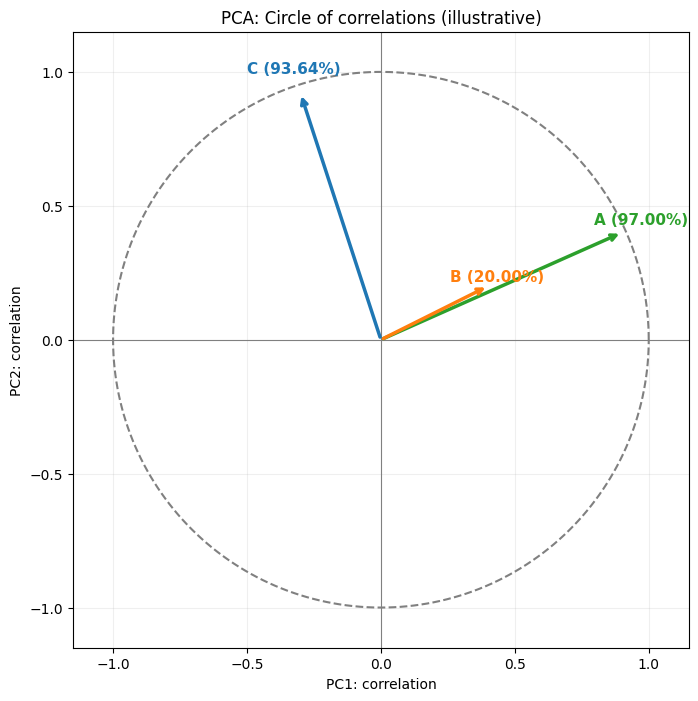

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Illustrative correlations with PC1 and PC2
correlations = pd.DataFrame({
    "Variable": ["A", "B", "C"],
    "PC1": [0.90, 0.40, -0.30],
    "PC2": [0.40, 0.20, 0.92]
})

# Calculate the squared correlations
correlations["PC1²"] = correlations["PC1"] ** 2
correlations["PC2²"] = correlations["PC2"] ** 2

# Squared radius = proportion of variance represented
correlations["r²"] = (
    correlations["PC1²"] + correlations["PC2²"]
)

# Arrow length
correlations["r"] = np.sqrt(correlations["r²"])

# Percentage of variance represented on the factorial plane
correlations["Explained (%)"] = correlations["r²"] * 100

display(Markdown("### Correlation circle calculations"))
display(correlations.round(4))

# Plot the unit circle
fig, ax = plt.subplots(figsize=(8, 8))

theta = np.linspace(0, 2 * np.pi, 500)
ax.plot(np.cos(theta), np.sin(theta),
        color="grey", linestyle="--", label="Unit circle")

# Principal component axes
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)

colors = ["tab:green", "tab:orange", "tab:blue"]

for (_, row), color in zip(correlations.iterrows(), colors):
    x, y = row["PC1"], row["PC2"]

    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2.5
        )
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        f"{row['Variable']} ({row['Explained (%)']:.2f}%)",
        color=color,
        fontsize=11,
        fontweight="bold",
        ha="center"
    )

ax.set(
    xlabel="PC1: correlation",
    ylabel="PC2: correlation",
    title="PCA: Circle of correlations (illustrative)"
)

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
plt.show()


In [2]:
display(Markdown(r"""
### Calculating the arrow lengths in the correlation circle

For each original variable $X_j$, the arrow coordinates are its correlations
with the first two principal components:

$$
x_j = \operatorname{Corr}(X_j, PC1)
$$

$$
y_j = \operatorname{Corr}(X_j, PC2)
$$

Using the Pythagorean theorem, the **squared distance** from the origin is:

$$
r_j^2 = x_j^2 + y_j^2
$$

Therefore, the **arrow length** is:

$$
r_j = \sqrt{x_j^2 + y_j^2}
$$

For standardised variables, $r_j^2$ represents the proportion of variance
of variable $X_j$ explained by PC1 and PC2 together.

An arrow close to the circumference ($r \approx 1$) indicates that
the variable is well represented on the factorial plane.
"""))

# Generate mathematical calculations dynamically from the DataFrame.
for _, row in correlations.iterrows():
    variable = row["Variable"]
    pc1 = row["PC1"]
    pc2 = row["PC2"]
    r_squared = row["r²"]
    radius = row["r"]
    percentage = row["Explained (%)"]

    display(Markdown(rf"""
#### Variable {variable}

**Step 1: Calculate the squared distance**

$$
\begin{{aligned}}
r_{{{variable}}}^2
&= \operatorname{{Corr}}({variable},PC1)^2
 + \operatorname{{Corr}}({variable},PC2)^2 \\[6pt]
&= ({pc1:.2f})^2 + ({pc2:.2f})^2 \\[6pt]
&= {pc1**2:.4f} + {pc2**2:.4f} \\[6pt]
&= {r_squared:.4f}
\end{{aligned}}
$$

**Step 2: Calculate the arrow length**

$$
r_{{{variable}}}
= \sqrt{{{r_squared:.4f}}}
\approx {radius:.4f}
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{{RepresentedVariance}}({variable})
= r_{{{variable}}}^2 \times 100
= {percentage:.2f}\%
$$

**Conclusion:** PC1 and PC2 together represent **{percentage:.2f}%**
of the variance of variable **{variable}**.
"""))



### Calculating the arrow lengths in the correlation circle

For each original variable $X_j$, the arrow coordinates are its correlations
with the first two principal components:

$$
x_j = \operatorname{Corr}(X_j, PC1)
$$

$$
y_j = \operatorname{Corr}(X_j, PC2)
$$

Using the Pythagorean theorem, the **squared distance** from the origin is:

$$
r_j^2 = x_j^2 + y_j^2
$$

Therefore, the **arrow length** is:

$$
r_j = \sqrt{x_j^2 + y_j^2}
$$

For standardised variables, $r_j^2$ represents the proportion of variance
of variable $X_j$ explained by PC1 and PC2 together.

An arrow close to the circumference ($r \approx 1$) indicates that
the variable is well represented on the factorial plane.



#### Variable A

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{A}^2
&= \operatorname{Corr}(A,PC1)^2
 + \operatorname{Corr}(A,PC2)^2 \\[6pt]
&= (0.90)^2 + (0.40)^2 \\[6pt]
&= 0.8100 + 0.1600 \\[6pt]
&= 0.9700
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{A}
= \sqrt{0.9700}
\approx 0.9849
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(A)
= r_{A}^2 \times 100
= 97.00\%
$$

**Conclusion:** PC1 and PC2 together represent **97.00%**
of the variance of variable **A**.



#### Variable B

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{B}^2
&= \operatorname{Corr}(B,PC1)^2
 + \operatorname{Corr}(B,PC2)^2 \\[6pt]
&= (0.40)^2 + (0.20)^2 \\[6pt]
&= 0.1600 + 0.0400 \\[6pt]
&= 0.2000
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{B}
= \sqrt{0.2000}
\approx 0.4472
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(B)
= r_{B}^2 \times 100
= 20.00\%
$$

**Conclusion:** PC1 and PC2 together represent **20.00%**
of the variance of variable **B**.



#### Variable C

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{C}^2
&= \operatorname{Corr}(C,PC1)^2
 + \operatorname{Corr}(C,PC2)^2 \\[6pt]
&= (-0.30)^2 + (0.92)^2 \\[6pt]
&= 0.0900 + 0.8464 \\[6pt]
&= 0.9364
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{C}
= \sqrt{0.9364}
\approx 0.9677
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(C)
= r_{C}^2 \times 100
= 93.64\%
$$

**Conclusion:** PC1 and PC2 together represent **93.64%**
of the variance of variable **C**.
